# SNOTEL station distribution in the Sierra Nevada box

Spatial and temporal coverage of the SNOTEL stations fetched by
`get_snotel_box.py` (any state, filtered to the Sierra Nevada bounding box),
reading `snotel_box_stations.csv` and `snotel_box_swe_wy1990-2026.csv`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
DATA_DIR = '/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/'

# Sierra Nevada bounding box, ERA5 (0-360) longitude convention -- same as
# get_snotel_box.py / plot_ca_box_map.ipynb
SIERRA_LAT_S, SIERRA_LAT_N = 34.5, 40.0
SIERRA_LON_W, SIERRA_LON_E = 239.0, 243.5
LON_W, LON_E = SIERRA_LON_W - 360.0, SIERRA_LON_E - 360.0

stations = pd.read_csv(DATA_DIR + 'snotel_box_stations.csv')
stations['state'] = stations['stationTriplet'].str.split(':').str[1]
stations['beginDate'] = pd.to_datetime(stations['beginDate'])

swe = pd.read_csv(DATA_DIR + 'snotel_box_swe_wy1990-2026.csv', parse_dates=['date'])

print(f'{len(stations)} stations, {stations["state"].value_counts().to_dict()}')
stations.sort_values('latitude', ascending=False).reset_index(drop=True)

36 stations, {'CA': 30, 'NV': 6}


,stationTriplet,name,elevation_ft,latitude,longitude,beginDate,state
0,540:CA:SNTL,Independence Creek,6440.0,39.49001,-120.28226,1980-10-01,CA
1,2170:NV:SNTL,Porter Canyon,7190.0,39.46544,-117.62069,2009-10-22,NV
2,340:NV:SNTL,Big Meadow,8240.0,39.45500,-119.94220,1983-10-01,NV
3,539:CA:SNTL,Independence Camp,6970.0,39.45269,-120.29367,1978-10-01,CA
4,541:CA:SNTL,Independence Lake,8340.0,39.42752,-120.31342,1978-10-01,CA
5,428:CA:SNTL,Css Lab,6890.0,39.32565,-120.36807,1980-10-01,CA
6,652:NV:SNTL,Mt Rose Ski Area,8810.0,39.31573,-119.89473,1980-10-01,NV
7,834:CA:SNTL,Truckee #2,6500.0,39.30087,-120.18407,1980-10-01,CA
8,337:NV:SNTL,Big Creek Sum,8710.0,39.29148,-117.11506,1980-10-01,NV
9,1242:NV:SNTL,Little Valley,6500.0,39.25259,-119.87710,2013-10-01,NV


## Spatial distribution

In [3]:
# terrain height from the ERA5 invariant surface geopotential, cropped to the
# Sierra box with a margin (same source as plot_ca_box_map.ipynb)
G = 9.80665  # m/s^2

flnm_invariant = (
    '/glade/campaign/collections/rda/data/d633000/e5.oper.invariant/197901/'
    'e5.oper.invariant.128_129_z.ll025sc.1979010100_1979010100.nc'
)

# ERA5 invariant longitude is in 0-360; select with that convention, then
# shift the coordinate to -180/180 to match the station lat/lon below
MAP_LON_W_360, MAP_LON_E_360 = SIERRA_LON_W - 2.0, SIERRA_LON_E + 2.0
MAP_LAT_S, MAP_LAT_N = SIERRA_LAT_S - 1.5, SIERRA_LAT_N + 1.5

with xr.open_dataset(flnm_invariant) as ds:
    elevation = (ds['Z'].isel(time=0) / G).sel(
        latitude=slice(MAP_LAT_N, MAP_LAT_S),
        longitude=slice(MAP_LON_W_360, MAP_LON_E_360),
    ).load()
elevation = elevation.assign_coords(longitude=elevation['longitude'] - 360.0)
elevation = elevation.clip(min=0)

MAP_LON_W, MAP_LON_E = MAP_LON_W_360 - 360.0, MAP_LON_E_360 - 360.0

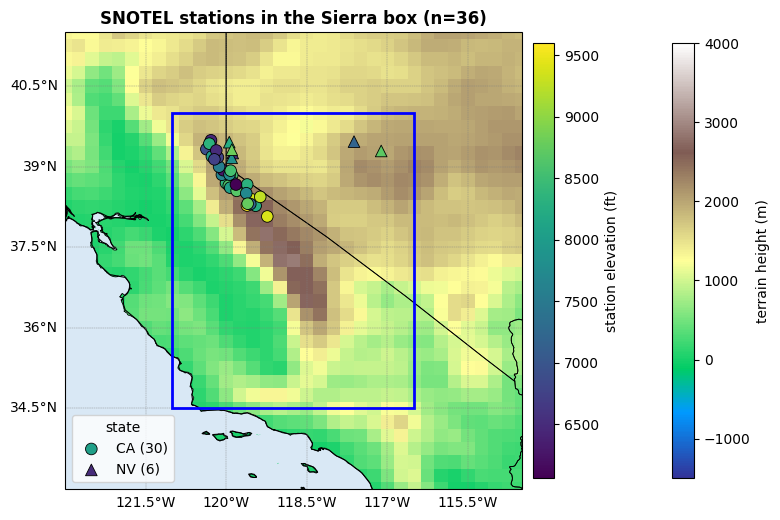

In [4]:
fig = plt.figure(figsize=(8, 9))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([MAP_LON_W, MAP_LON_E, MAP_LAT_S, MAP_LAT_N], crs=ccrs.PlateCarree())

terrain = ax.pcolormesh(
    elevation['longitude'], elevation['latitude'], elevation,
    cmap='terrain', vmin=-1500, vmax=4000,
    shading='auto', transform=ccrs.PlateCarree(), zorder=0,
)
cbar = plt.colorbar(terrain, ax=ax, orientation='vertical', shrink=0.5, pad=0.08)
cbar.set_label('terrain height (m)')

ax.add_feature(cfeature.OCEAN, facecolor='#d9e8f5', zorder=1)
ax.coastlines(resolution='50m', linewidth=0.8, zorder=2)
ax.add_feature(cfeature.STATES, linewidth=0.6, edgecolor='black', zorder=2)

box = mpatches.Rectangle(
    (SIERRA_LON_W, SIERRA_LAT_S), SIERRA_LON_E - SIERRA_LON_W, SIERRA_LAT_N - SIERRA_LAT_S,
    linewidth=2, edgecolor='blue', facecolor='none', zorder=3,
    transform=ccrs.PlateCarree(),
)
ax.add_patch(box)

markers = {'CA': 'o', 'NV': '^'}
for state, grp in stations.groupby('state'):
    sc = ax.scatter(
        grp['longitude'], grp['latitude'], c=grp['elevation_ft'],
        cmap='viridis', vmin=stations['elevation_ft'].min(), vmax=stations['elevation_ft'].max(),
        s=70, marker=markers.get(state, 's'), edgecolor='black', linewidth=0.6,
        transform=ccrs.PlateCarree(), zorder=4, label=f'{state} ({len(grp)})',
    )

cbar2 = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.5, pad=0.02)
cbar2.set_label('station elevation (ft)')

gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle='--', color='gray')
gl.top_labels = False
gl.right_labels = False

ax.legend(loc='lower left', title='state')
ax.set_title(f'SNOTEL stations in the Sierra box (n={len(stations)})',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

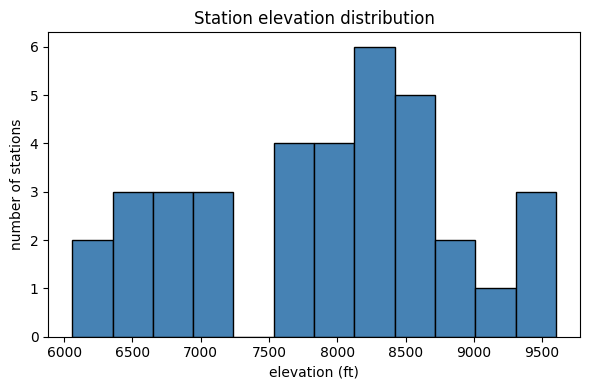

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(stations['elevation_ft'], bins=12, color='steelblue', edgecolor='black')
ax.set_xlabel('elevation (ft)')
ax.set_ylabel('number of stations')
ax.set_title('Station elevation distribution')
plt.tight_layout()
plt.show()

## Temporal distribution

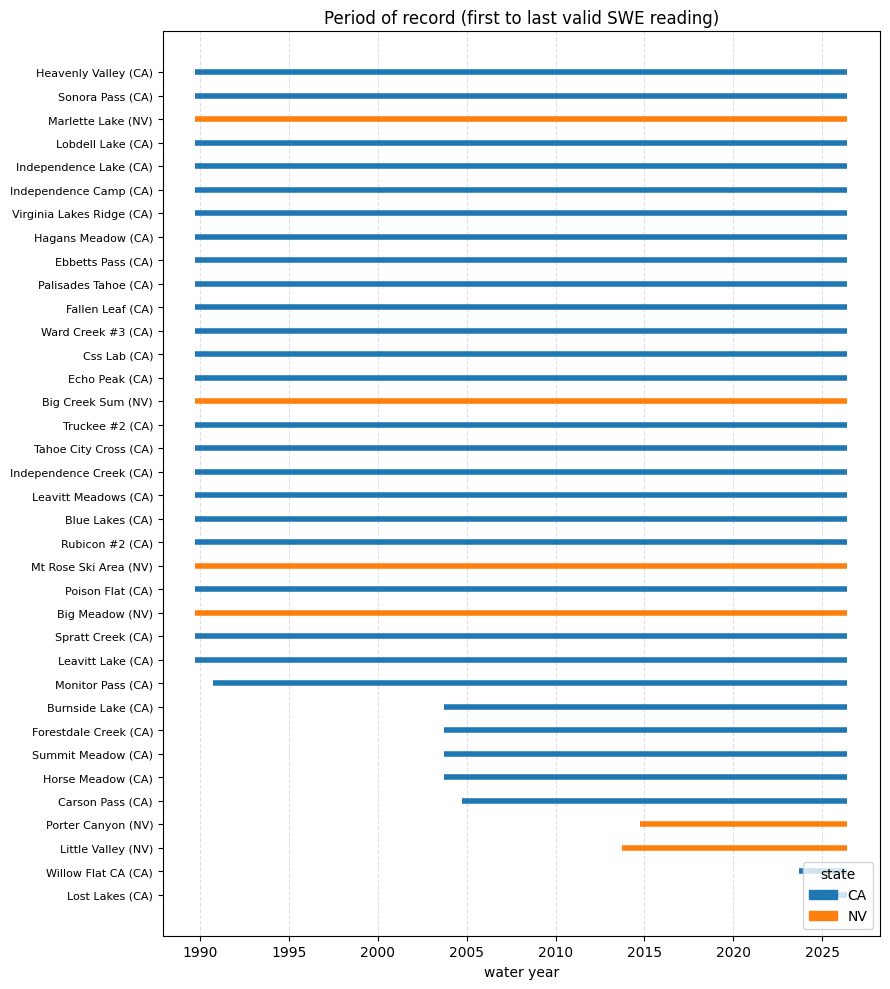

In [6]:
# per-station period of record: official beginDate vs. first/last day with a
# valid (non-null) SWE reading in the fetched data
valid = swe.dropna(subset=['swe_mm'])
span = valid.groupby('stationTriplet')['date'].agg(first_valid='min', last_valid='max')
record = stations.join(span, on='stationTriplet').sort_values('beginDate').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 10))
colors = {'CA': 'tab:blue', 'NV': 'tab:orange'}
for i, row in record.iterrows():
    ax.plot([row['first_valid'], row['last_valid']], [i, i],
            color=colors.get(row['state'], 'gray'), linewidth=4, solid_capstyle='butt')

ax.set_yticks(range(len(record)))
ax.set_yticklabels(record['name'] + ' (' + record['state'] + ')', fontsize=8)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('water year')
ax.set_title('Period of record (first to last valid SWE reading)')
ax.grid(axis='x', linestyle='--', alpha=0.4)

handles = [mpatches.Patch(color=c, label=s) for s, c in colors.items()]
ax.legend(handles=handles, loc='lower right', title='state')
plt.tight_layout()
plt.show()

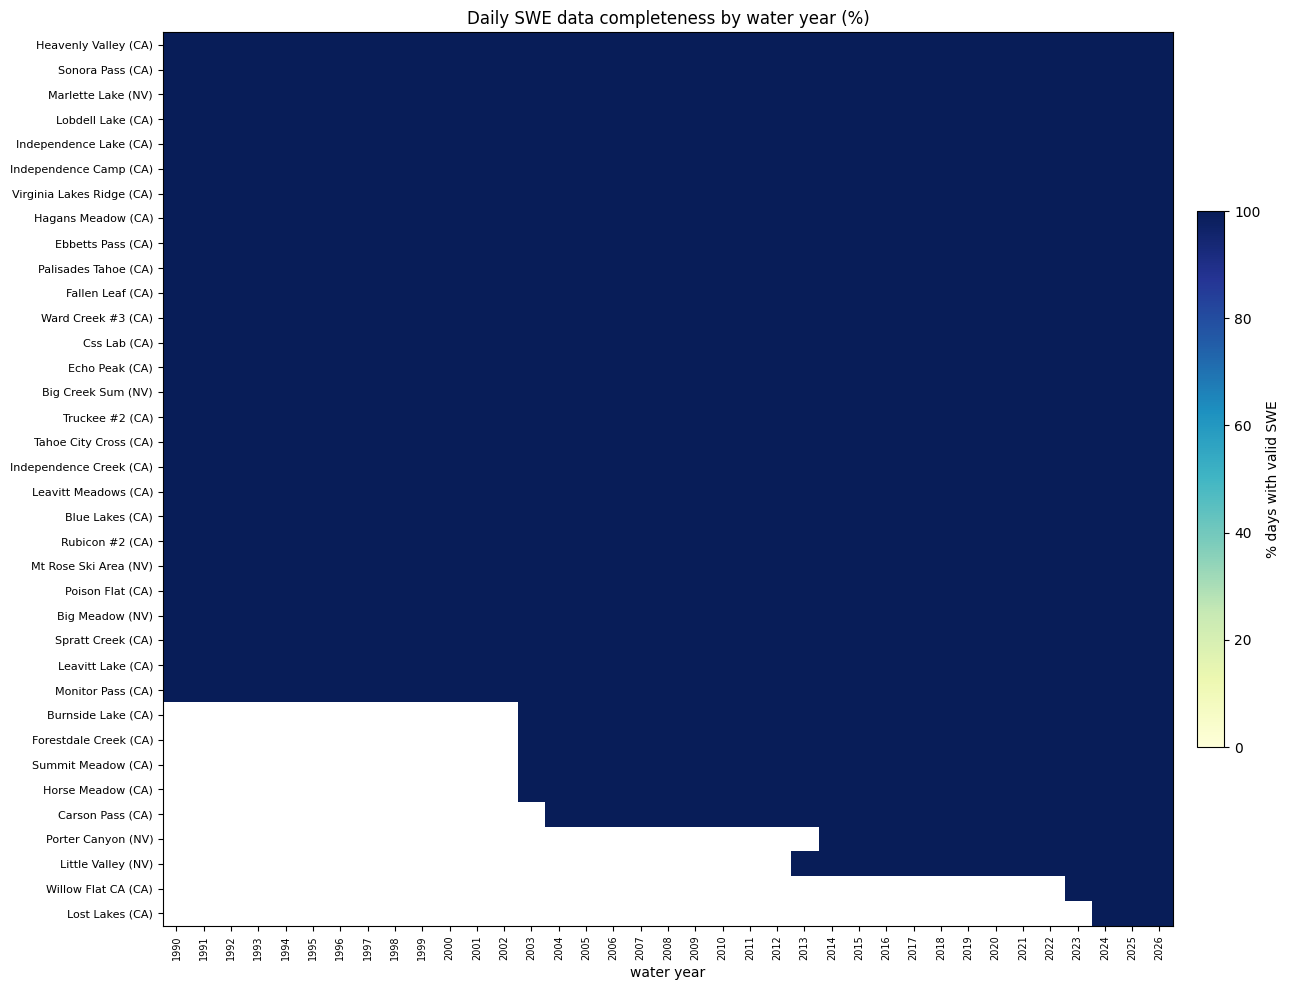

In [7]:
# yearly data completeness: % of days per water year with a valid SWE value
swe['water_year'] = swe['date'].dt.year + (swe['date'].dt.month >= 10).astype(int)

completeness = (
    swe.assign(has_val=swe['swe_mm'].notna())
       .groupby(['stationTriplet', 'water_year'])['has_val']
       .mean()
       .mul(100)
       .unstack('water_year')
)
completeness = completeness.reindex(record['stationTriplet']).set_axis(
    record['name'] + ' (' + record['state'] + ')', axis=0
)

fig, ax = plt.subplots(figsize=(14, 10))
im = ax.imshow(completeness, aspect='auto', cmap='YlGnBu', vmin=0, vmax=100)
ax.set_xticks(range(len(completeness.columns)))
ax.set_xticklabels(completeness.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(completeness)))
ax.set_yticklabels(completeness.index, fontsize=8)
ax.set_xlabel('water year')
ax.set_title('Daily SWE data completeness by water year (%)')
cbar = plt.colorbar(im, ax=ax, orientation='vertical', shrink=0.6, pad=0.02)
cbar.set_label('% days with valid SWE')
plt.tight_layout()
plt.show()